### MUSIC RECOMMENDATION ENGINE (COSINE SIMILARITY)

## Data Loading and Library Setup

This section initializes the environment by importing required libraries and loading the final dataset.

---

### Libraries Used

- Data handling and manipulation  
- String processing and pattern matching  
- Data structures for aggregation  
- Feature scaling and transformation  
- Similarity computation for recommendation  

---

### Dataset Loading

- Loads the final processed dataset containing songs and cleaned genres  
- This dataset serves as the input for feature engineering and recommendation modeling  

---

### Purpose

- Prepares the workspace for building the recommendation system  
- Ensures all required tools and data are available for subsequent steps  

In [1]:
import pandas as pd
import ast
import re
from collections import defaultdict
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.metrics.pairwise import cosine_similarity

df = pd.read_csv("songs_with_genres_final.csv")

## Data Preprocessing Helpers

This section prepares helper logic for consistent data formatting and cleaning.

---

### List Conversion

- Ensures that artist data is represented as a list  
- Converts string representations into structured lists when necessary  
- Handles parsing errors by falling back to a default format  

---

### Text Normalization

- Standardizes text fields such as track names  
- Converts text to lowercase  
- Removes punctuation and unwanted characters  
- Trims extra whitespace  

---

### Column Preparation

- Applies list conversion to the artist column  
- Creates a cleaned version of track names for consistent processing  

---

### Purpose

- Ensures uniform data structure across the dataset  
- Reduces inconsistencies caused by formatting variations  
- Prepares data for accurate matching and feature extraction  

In [2]:
def ensure_list(x):
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except:
            return [x]
    return x

def normalize_name(x):
    x = x.lower()
    x = re.sub(r'[^\w\s]', '', x)
    return x.strip()

df['artists'] = df['artists'].apply(ensure_list)
df['name_clean'] = df['name'].str.strip().str.lower()


## Genre Multi-Label Encoding

This section converts genre information into a numerical format suitable for machine learning models.

---

### Genre List Preparation

- Splits the genre string into individual labels  
- Removes empty values and extra whitespace  
- Stores genres as a list for each track  

---

### Multi-Label Encoding

- Applies a multi-label binarization technique to transform genres into binary features  
- Each unique genre becomes a separate column  
- A value of 1 indicates the presence of that genre for a track  

---

### Feature Weighting

- Scales genre features by a constant factor  
- Adjusts the influence of genre similarity in the recommendation process  

---

### Data Integration

- Combines the generated genre feature matrix with the original dataset  
- Ensures all features are available in a single unified structure  

---

### Purpose

- Converts categorical genre data into a machine-readable format  
- Enables similarity calculations using numerical vectors  
- Forms the foundation for content-based recommendation models  

In [3]:
df['genre_list'] = df['genres_filtered'].fillna('').apply(
    lambda x: [g.strip() for g in x.split(',') if g]
)

mlb = MultiLabelBinarizer()
genre_matrix = mlb.fit_transform(df['genre_list'])
genre_df = pd.DataFrame(genre_matrix, columns=mlb.classes_) * 0.5

df = pd.concat([df, genre_df], axis=1)

## Feature Engineering and Scaling

This section prepares the final feature set used for similarity computation in the recommendation system.

---

### Feature Selection

- Combines two types of features:
  - Audio features such as danceability, energy, tempo, and others  
  - Genre-based features generated from multi-label encoding  

---

### Handling Missing Values

- Replaces missing values with zero  
- Ensures a complete feature matrix without null entries  

---

### Feature Scaling

- Applies standardization to normalize feature values  
- Transforms features to have zero mean and unit variance  
- Prevents features with larger scales from dominating similarity calculations  

---

### Feature Matrix Creation

- Produces a numerical feature matrix representing each track  
- Converts data into a format suitable for efficient computation  

---

### Purpose

- Creates a balanced and normalized representation of each track  
- Combines content (audio) and categorical (genre) information  
- Prepares data for similarity-based recommendation methods such as cosine similarity  

In [4]:
base_features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness',
    'valence', 'tempo', 'popularity'
]

features = base_features + list(genre_df.columns)

df[features] = df[features].fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features]).astype('float32')


## Artist-Based Adjustments

This section defines helper logic and weighting strategies to incorporate artist relationships into the recommendation process.

---

### Main Artist Extraction

- Identifies the primary artist from a list of artists  
- Uses the first artist as the representative for the track  

---

### Artist Similarity Check

- Determines whether two tracks share at least one common artist  
- Uses set-based comparison for efficient matching  

---

### Weighting Strategy

- Applies a positive weight for collaborations:
  - Slightly boosts similarity when tracks share artists  

- Applies a penalty for same-artist tracks:
  - Reduces similarity to avoid over-recommending songs from the same artist  

---

### Purpose

- Introduces diversity into recommendations  
- Prevents dominance of a single artist in results  
- Still allows meaningful connections through collaborations  

In [5]:
# ---------- ARTIST HELPERS ----------
def get_main_artist(lst):
    return lst[0] if isinstance(lst, list) and lst else None

def has_common_artist(a, b):
    return len(set(a) & set(b)) > 0

# ---------- WEIGHTS ----------
COLLAB_WEIGHT = 0.15
SAME_ARTIST_PENALTY = 0.1

## Recommendation Function

This section implements the core logic for generating song recommendations based on feature similarity and artist relationships.

---

### Input Handling

- Accepts a song name and an optional artist name  
- Normalizes the input for consistent matching  
- Filters the dataset to find the correct song entry  
- If multiple matches exist, selects the most popular one  

---

### Similarity Computation

- Uses the precomputed feature matrix to represent songs numerically  
- Computes similarity scores between the input song and all other songs  
- Relies on cosine similarity to measure closeness  

---

### Artist-Based Adjustments

- Identifies the main artist of the input song  
- Applies:
  - A penalty to reduce recommendations from the same artist  
  - A bonus to promote songs with shared or collaborating artists  

---

### Score Refinement

- Combines similarity scores with artist-based adjustments  
- Ensures the input song itself is excluded from results  

---

### Deduplication and Diversity Control

- Removes duplicate song entries  
- Limits the number of recommendations per artist  
- Ensures a balanced and diverse recommendation list  

---

### Result Selection

- Sorts songs based on final scores  
- Selects the top recommendations based on the requested count  

---

### Output

- Returns structured results including:
  - Song ID  
  - Name  
  - Artists  
  - Genres  
  - Popularity  

---

### Testing

- Demonstrates the function using a sample input  
- Prints formatted recommendations for inspection  

---

### Purpose

- Combines content-based similarity with artist-aware adjustments  
- Produces diverse and relevant song recommendations  
- Forms the core component of the recommendation system  

In [6]:
def recommend_songs(song_name, artist_name=None, num_recommendations=5):

    song_name_clean = song_name.strip().lower()

    matches = df[df['name_clean'] == song_name_clean]

    if artist_name:
        matches = matches[matches['artists'].apply(
            lambda x: artist_name.lower() in [a.lower() for a in x]
        )]

    if matches.empty:
        print("Song not found")
        return []

    idx = matches.sort_values(by='popularity', ascending=False).index[0]

    # similarity
    query_vec = X_scaled[idx].reshape(1, -1)
    similarities = cosine_similarity(query_vec, X_scaled)[0]

    # artist logic
    input_artists = df.loc[idx, 'artists']
    main_artist = get_main_artist(input_artists)

    same_artist = df['artists'].apply(
        lambda x: main_artist in x if main_artist else False
    ).astype(int)

    same_artist_penalty = same_artist * SAME_ARTIST_PENALTY

    collab_bonus = df['artists'].apply(
        lambda x: has_common_artist(x, input_artists)
    ).astype(int) * COLLAB_WEIGHT

    final_scores = similarities + collab_bonus - same_artist_penalty

    # remove itself
    final_scores[idx] = -1

    sorted_indices = final_scores.argsort()[::-1]

    seen_tracks = set()
    artist_count = defaultdict(int)
    top_indices = []

    for idx_candidate in sorted_indices:
        name = normalize_name(df.loc[idx_candidate, 'name'])
        artist = get_main_artist(df.loc[idx_candidate, 'artists'])

        if artist is None:
            continue

        key = (name, artist)

        if key in seen_tracks:
            continue

        if artist_count[artist] >= 2:
            continue

        seen_tracks.add(key)
        artist_count[artist] += 1
        top_indices.append(idx_candidate)

        if len(top_indices) >= num_recommendations:
            break

    results = df.loc[top_indices][
        ['id', 'name', 'artists', 'genres_filtered', 'popularity']
    ].to_dict(orient='records')

    return results


# ---------- TEST ----------
recs = recommend_songs("DNA.", "Kendrick Lamar", 5)

for i, song in enumerate(recs, 1):
    print(f"Recommendation {i}")
    print(f"Name       : {song['name']}")
    print(f"Artists    : {', '.join(song['artists'])}")
    print(f"Genres     : {song['genres_filtered']}")
    print(f"Popularity : {song['popularity']}")
    print("-" * 50)

Recommendation 1
Name       : XXX. FEAT. U2.
Artists    : Kendrick Lamar, U2
Genres     : conscious hip hop, experimental hip hop, hardcore hip hop, hip hop, jazz hip hop, political hip hop, west coast hip hop
Popularity : 65
--------------------------------------------------
Recommendation 2
Name       : The Blacker The Berry
Artists    : Kendrick Lamar
Genres     : boom bap, conscious hip hop, hardcore hip hop, hip hop, political hip hop, west coast hip hop
Popularity : 61
--------------------------------------------------
Recommendation 3
Name       : B.O.B. - Bombs Over Baghdad
Artists    : OutKast
Genres     : conscious hip hop, drum and bass, experimental hip hop, hardcore hip hop, hip hop, political hip hop, rap rock, southern hip hop
Popularity : 64
--------------------------------------------------
Recommendation 4
Name       : TEMPTATION
Artists    : Joey Bada$$
Genres     : banned, conscious hip hop, east coast hip hop, hip hop, neo soul, political hip hop, pop rap
Popularit

### GRAPHS AND ANALYSIS  
Here we have analyzed our recommnedations by comparing them against the input song like a line plot, radar comparison, heatmap etc.

In [25]:
def compare_features_scaled(input_idx, rec_indices):

    feature_names = base_features
    feature_indices = list(range(len(base_features)))  # first columns in X_scaled

    plt.figure(figsize=(10, 5))

    # input
    input_vals = X_scaled[input_idx, feature_indices]
    plt.plot(feature_names, input_vals, marker='o', label='Input')

    # recommendations
    for i, idx in enumerate(rec_indices):
        rec_vals = X_scaled[idx, feature_indices]
        plt.plot(feature_names, rec_vals, marker='o', alpha=0.7, label=f'Rec {i+1}')

    plt.xticks(rotation=45)
    plt.title("Scaled Audio Feature Comparison")
    plt.legend()
    plt.show()

In [26]:
import seaborn as sns

def heatmap_compare_scaled(input_idx, rec_indices):

    indices = [input_idx] + list(rec_indices)
    labels = ["Input"] + [f"Rec {i+1}" for i in range(len(rec_indices))]

    feature_indices = list(range(len(base_features)))
    data = X_scaled[indices][:, feature_indices]

    plt.figure(figsize=(8, 4))
    sns.heatmap(data, yticklabels=labels, xticklabels=base_features, cmap="coolwarm")
    plt.title("Scaled Feature Heatmap")
    plt.show()

### Genre comparison and Jaccard similarity  
In this we have taken the input song and compared the common genres with our recommended songs to analyse the affect of genres in our engine  
We have used a Jaccard Score which divides the No. of common genres by No. of total unique genres between the both of them

In [33]:
def compare_genres(input_idx, rec_indices):

    input_name = df.loc[input_idx, 'name']
    input_artist = ", ".join(df.loc[input_idx, 'artists'])
    input_genres = set(df.loc[input_idx, 'genre_list'])

    print("INPUT SONG")
    print(f"Name   : {input_name}")
    print(f"Artist : {input_artist}")
    print(f"Genres : {', '.join(input_genres)}")
    print("-" * 50)

    for i, idx in enumerate(rec_indices):

        rec_name = df.loc[idx, 'name']
        rec_artist = ", ".join(df.loc[idx, 'artists'])
        rec_genres = set(df.loc[idx, 'genre_list'])

        overlap = input_genres & rec_genres
        union = input_genres | rec_genres

        similarity = len(overlap) / len(union) if union else 0

        print(f"\nRecommendation {i+1}")
        print(f"Name       : {rec_name}")
        print(f"Artists    : {rec_artist}")
        print(f"Genres     : {', '.join(rec_genres)}")
        print(f"Common     : {', '.join(overlap) if overlap else 'None'}")
        print(f"Jaccard    : {round(similarity, 3)}")
        print("-" * 50)

In [31]:
def radar_compare_scaled(input_idx, rec_indices):

    import numpy as np

    features_to_plot = base_features[:6]
    feature_indices = [base_features.index(f) for f in features_to_plot]

    angles = np.linspace(0, 2*np.pi, len(features_to_plot), endpoint=False).tolist()
    angles += angles[:1]

    plt.figure(figsize=(6,6))

    # ---------- INPUT ----------
    input_vals = X_scaled[input_idx, feature_indices].tolist()
    input_vals += input_vals[:1]

    plt.plot(angles, input_vals, linewidth=2, label="Input")
    plt.fill(angles, input_vals, alpha=0.2)  # transparent fill

    # ---------- RECOMMENDATIONS ----------
    for i, idx in enumerate(rec_indices):
        vals = X_scaled[idx, feature_indices].tolist()
        vals += vals[:1]

        plt.plot(angles, vals, linewidth=1.5, alpha=0.8, label=f"Rec {i+1}")
        plt.fill(angles, vals, alpha=0.1)  # lighter fill

    plt.xticks(angles[:-1], features_to_plot)
    plt.title("Scaled Radar Comparison (Filled)")
    plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
    plt.show()

In [29]:
def recommend_songs_indices(song_name, artist_name=None, num_recommendations=5):

    song_name_clean = song_name.strip().lower()

    matches = df[df['name_clean'] == song_name_clean]

    if artist_name:
        matches = matches[matches['artists'].apply(
            lambda x: artist_name.lower() in [a.lower() for a in x]
        )]

    if matches.empty:
        print("Song not found")
        return []

    idx = matches.sort_values(by='popularity', ascending=False).index[0]

    # similarity
    query_vec = X_scaled[idx].reshape(1, -1)
    similarities = cosine_similarity(query_vec, X_scaled)[0]

    # artist logic
    input_artists = df.loc[idx, 'artists']
    main_artist = get_main_artist(input_artists)

    same_artist = df['artists'].apply(
        lambda x: main_artist in x if main_artist else False
    ).astype(int)

    same_artist_penalty = same_artist * SAME_ARTIST_PENALTY

    collab_bonus = df['artists'].apply(
        lambda x: has_common_artist(x, input_artists)
    ).astype(int) * COLLAB_WEIGHT

    final_scores = similarities + collab_bonus - same_artist_penalty

    final_scores[idx] = -1

    sorted_indices = final_scores.argsort()[::-1]

    seen_tracks = set()
    artist_count = defaultdict(int)
    top_indices = []

    for idx_candidate in sorted_indices:
        name = normalize_name(df.loc[idx_candidate, 'name'])
        artist = get_main_artist(df.loc[idx_candidate, 'artists'])

        if artist is None:
            continue

        key = (name, artist)

        if key in seen_tracks:
            continue

        if artist_count[artist] >= 2:
            continue

        seen_tracks.add(key)
        artist_count[artist] += 1
        top_indices.append(idx_candidate)

        if len(top_indices) >= num_recommendations:
            break

    return idx, top_indices

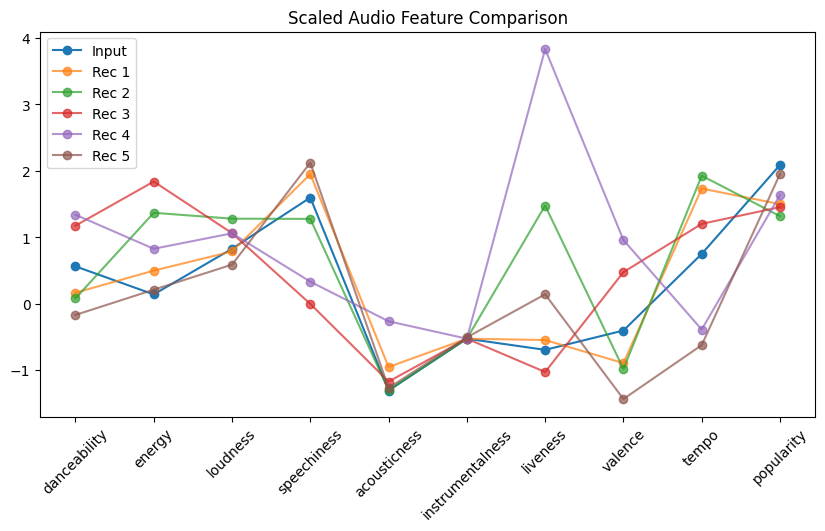

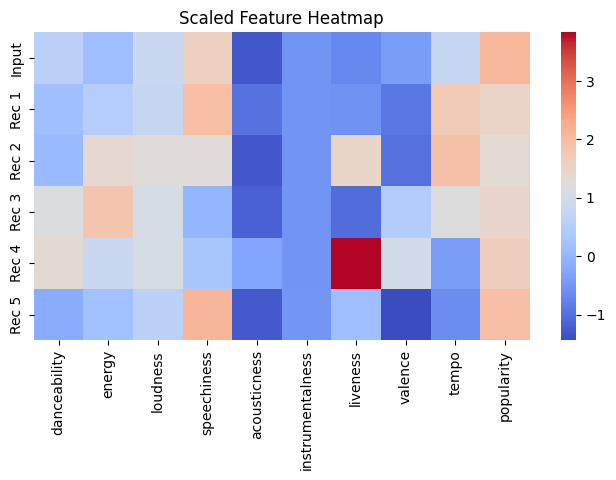

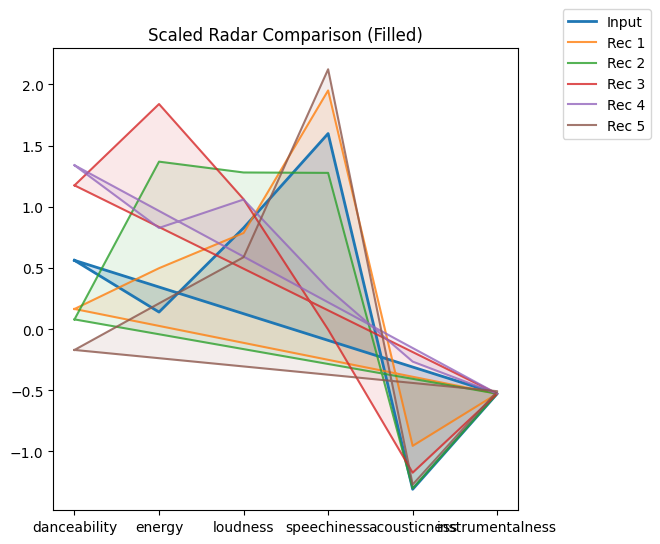

INPUT SONG
Name   : DNA.
Artist : Kendrick Lamar
Genres : trap, west coast hip hop, hip hop, political hip hop, conscious hip hop, hardcore hip hop
--------------------------------------------------

Recommendation 1
Name       : XXX. FEAT. U2.
Artists    : Kendrick Lamar, U2
Genres     : west coast hip hop, hip hop, political hip hop, jazz hip hop, experimental hip hop, conscious hip hop, hardcore hip hop
Common     : west coast hip hop, hip hop, political hip hop, conscious hip hop, hardcore hip hop
Jaccard    : 0.625
--------------------------------------------------

Recommendation 2
Name       : The Blacker The Berry
Artists    : Kendrick Lamar
Genres     : west coast hip hop, hip hop, political hip hop, boom bap, conscious hip hop, hardcore hip hop
Common     : west coast hip hop, hip hop, political hip hop, conscious hip hop, hardcore hip hop
Jaccard    : 0.714
--------------------------------------------------

Recommendation 3
Name       : B.O.B. - Bombs Over Baghdad
Artists  

In [34]:
idx, recs = recommend_songs_indices("DNA.", "Kendrick Lamar", 5)

compare_features_scaled(idx, recs)
heatmap_compare_scaled(idx, recs)
radar_compare_scaled(idx, recs)
compare_genres(idx, recs) 